# Trabajo Práctico Final 2026 — Fase 3: Modelado

**Predicción del consumo diario de refrigeración para el día siguiente (D+1).**  
**Laboratorio de Datos II** · Validación temporal, baselines, optimización con Optuna y registro de modelos.

Este notebook documenta y reproduce el análisis de la Fase 3 a partir de los resultados versionados en `results/experiment_logs.csv`, el CSV procesado de la Fase 2 y el modelo registrado en `models/`. La ejecución **no vuelve a correr los 85 ensayos de Optuna**, **no sobrescribe el modelo final** y **no evalúa Test**.

El código de entrenamiento completo está en `src/train_model.py`. El diagnóstico que genera los CSV y figuras también se puede reproducir con `src/diagnostico_validacion.py`.

## 1. Planteo y criterio de evaluación

El problema es de regresión supervisada. Con las mediciones del día **D** estimamos `target_manana`, que corresponde al totalizador de frío al cierre de **D+1**. La agregación diaria y la limpieza de los registros se justificaron en las fases anteriores.

Se utiliza una división **temporal**, sin mezclar fechas:

| Partición | Observaciones | Uso |
|---|---:|---|
| Train | 736 | Ajuste del modelo y del escalador |
| Validation | 157 | Comparación y elección de hiperparámetros |
| Test | 159 | Reservado para una evaluación final, fuera de este notebook |

Las 22 características del dataset ya fueron seleccionadas en la Fase 2. El criterio principal de comparación indicado por la consigna es el **MAE** sobre Validation; también reportamos RMSE y R². Las métricas previas al reentrenamiento no son un resultado independiente del modelo final.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEMILLA = 42

# VS Code puede abrir el notebook con cwd en la raíz o dentro de notebooks/.
RAIZ = Path.cwd().resolve()
if not (RAIZ / "src" / "train_model.py").is_file():
    RAIZ = RAIZ.parent
if not (RAIZ / "src" / "train_model.py").is_file():
    raise FileNotFoundError("Abrí el notebook desde tp-final/ o tp-final/notebooks/.")
sys.path.insert(0, str(RAIZ))

DATASET = RAIZ / "data" / "processed" / "dataset_final.csv"
CHECKSUMS = RAIZ / "data" / "checksums.json"
LOGS = RAIZ / "results" / "experiment_logs.csv"
REGISTRY = RAIZ / "models" / "model_registry.json"

for ruta in (DATASET, CHECKSUMS, LOGS, REGISTRY):
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta el archivo requerido: {ruta.relative_to(RAIZ)}")

print("Proyecto:", RAIZ)
print("Semilla:", SEMILLA)

Proyecto: C:\Users\maxim\OneDrive\Desktop\tp-final
Semilla: 42


## 2. Integridad, procedencia y separación temporal

Verificamos que el CSV coincida con su SHA-256 registrado. Para evitar una falsa discrepancia entre Windows y Linux, se normalizan los saltos de línea **solo durante el cálculo del hash**, sin editar el archivo. Para el análisis se leen únicamente las primeras 893 observaciones, correspondientes a Train y Validation. **No se carga ni examina el objetivo de Test.**

In [2]:
from src.train_model import cargar_desarrollo, calcular_baselines, verificar_integridad

verificar_integridad()

datos, features = cargar_desarrollo()  # Lee exactamente 736 + 157 filas.
train = datos.loc[datos["particion"].eq("train")].copy()
val = datos.loc[datos["particion"].eq("validation")].copy()

with REGISTRY.open(encoding="utf-8") as f:
    registro = json.load(f)
version = registro["latest"]
entrada = registro["models"][version]

assert len(train) == 736 and len(val) == 157
assert len(features) == 22
assert features == entrada["features"], "El orden de las variables difiere del registro."
assert entrada["reentrenamiento"]["filas"] == 893
assert entrada["semilla"] == SEMILLA

print("Train:", train[features].shape)
print("Validation:", val[features].shape)
print("Variables finales:", len(features))
print("Modelo registrado:", version, "-", entrada["modelo"])
print("Test: reservado; no se cargó en este notebook.")

Integridad del dataset: OK
SHA-256 normalizado: 6ff74dd79ae0b5dece4944e1f5b4cb5723c2b700be2785863fd54083a4bf1d3c
Train: (736, 22)
Validation: (157, 22)
Variables finales: 22
Modelo registrado: v1.0.0 - LASSO
Test: reservado; no se cargó en este notebook.


## 3. Baselines obligatorios

**Persistencia:** mañana se pronostica el mismo consumo de frío que al cierre de hoy, `frio_kw`.

**Media móvil de siete días:** se promedian los consumos observados en los siete días calendario hasta D inclusive (`D-6, ..., D`). Si hay fechas sin registro, se promedian solo las disponibles; esta regla se documenta y se aplica de forma consistente. Ambas predicciones utilizan información disponible hasta D y se evalúan sobre **las mismas 157 fechas de Validation**.

Estas referencias permiten medir si vale la pena utilizar un algoritmo de mayor complejidad.

In [3]:
validacion_baselines, tabla_baselines = calcular_baselines(datos)
incompletas = int((validacion_baselines["observados_en_ventana"] < 7).sum())
display(tabla_baselines.drop(columns="hiperparametros").round(2))
print(f"Ventanas con menos de 7 días observados: {incompletas}/{len(val)}")
assert len(validacion_baselines) == len(val)

,modelo,particion,filas,MAE,RMSE,R2
0,Media movil 7 dias,validation,157,2492.70,3282.50,0.32
1,Persistencia,validation,157,2739.85,3419.28,0.26


Ventanas con menos de 7 días observados: 51/157


### Lectura de los baselines

En las ejecuciones de esta fase, la media móvil obtuvo **MAE ≈ 2.492,70** y persistencia **MAE ≈ 2.739,85** en Validation. La media móvil es una referencia más exigente que la persistencia. En **51 de las 157 ventanas** faltaba al menos una fecha calendario: no afirmamos que esos días tengan siete observaciones completas.

## 4. Tracking de experimentos

El archivo `results/experiment_logs.csv` conserva para cada ensayo: `timestamp_utc`, modelo, partición, cantidad de filas, MAE, RMSE, R², hiperparámetros, semilla y commit. **Varias filas representan ensayos o ejecuciones repetidas**; no son observaciones independientes ni evaluaciones de Test.

Mostramos la cantidad de registros, elegimos el menor MAE registrado en Validation para cada familia y recuperamos el espacio explorado a partir de los parámetros de cada ensayo.

In [4]:
logs = pd.read_csv(LOGS)
columnas_log = {
    "timestamp_utc", "modelo", "particion", "filas", "MAE", "RMSE", "R2",
    "hiperparametros", "semilla", "git_commit"
}
assert columnas_log.issubset(logs.columns), "El tracking tiene columnas faltantes."

for col in ("filas", "MAE", "RMSE", "R2", "semilla"):
    logs[col] = pd.to_numeric(logs[col], errors="coerce")

experimentacion = logs.loc[
    logs["particion"].eq("validation")
    & logs["filas"].eq(157)
    & logs["semilla"].eq(SEMILLA)
].dropna(subset=["MAE", "RMSE", "R2"]).copy()

assert not experimentacion.empty, "No hay experimentos de Validation válidos."
print("Registros totales del tracking:", len(logs))
print("Ensayos comparables (Validation, 157 filas, semilla 42):", len(experimentacion))
display(experimentacion.groupby("modelo").size().rename("registros").reset_index())

Registros totales del tracking: 219
Ensayos comparables (Validation, 157 filas, semilla 42): 219


,modelo,registros
0,LASSO,20
1,LightGBM (Optuna),30
2,Media movil 7 dias,5
3,Persistencia,5
4,Random Forest (Optuna),75
5,Ridge,24
6,XGBoost (Optuna),60


In [5]:
# Mejor fila registrada por familia: el criterio exigido es el MAE mínimo.
mejores = (
    experimentacion.loc[experimentacion.groupby("modelo")["MAE"].idxmin()]
    .sort_values("MAE").reset_index(drop=True)
)
comparacion = mejores[["modelo", "MAE", "RMSE", "R2", "filas"]].copy()
display(comparacion.round(2))

esperados = {
    "Persistencia", "Media movil 7 dias", "Ridge", "LASSO",
    "Random Forest (Optuna)", "XGBoost (Optuna)", "LightGBM (Optuna)",
}
assert esperados.issubset(set(comparacion["modelo"])), "Faltan modelos obligatorios en los logs."
assert comparacion.iloc[0]["modelo"] == "LASSO", "El modelo ganador registrado no es LASSO."

,modelo,MAE,RMSE,R2,filas
0,LASSO,2365.00,2961.56,0.45,157
1,Media movil 7 dias,2492.70,3282.50,0.32,157
2,Ridge,2494.85,3087.42,0.40,157
3,Random Forest (Optuna),2540.33,3110.43,0.39,157
4,XGBoost (Optuna),2581.72,3144.04,0.38,157
5,LightGBM (Optuna),2607.13,3231.81,0.34,157
6,Persistencia,2739.85,3419.28,0.26,157


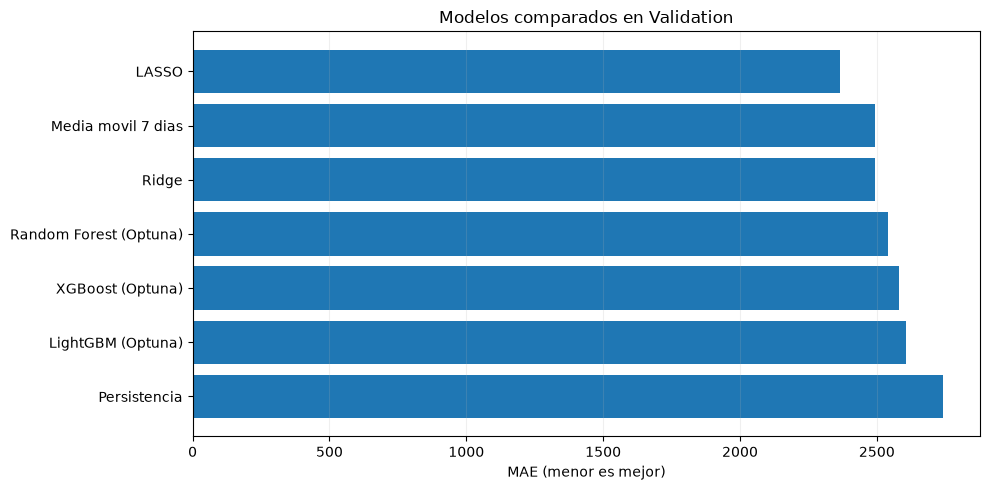

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ordenada = comparacion.sort_values("MAE", ascending=False)
ax.barh(ordenada["modelo"], ordenada["MAE"])
ax.set(title="Modelos comparados en Validation", xlabel="MAE (menor es mejor)")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación de la comparación

La mejor configuración de LASSO (`alpha=300`) obtuvo **MAE ≈ 2.365,00**, RMSE ≈ 2.961,56 y R² ≈ 0,447. Fue mejor que Ridge y que las mejores configuraciones registradas de Random Forest, XGBoost y LightGBM.

La ganancia frente a la media móvil de siete días fue de **unos 127,70 kW de MAE (5,12 %)**. Esa mejora es positiva, pero limitada: habrá que discutir si compensa la necesidad de mantener un modelo entrenado y un pipeline de inferencia. Los modelos de árboles no aprovecharon mejor estos 736 ejemplos de entrenamiento bajo los rangos ensayados; **no concluimos que esos algoritmos sean siempre inferiores**.

## 5. Búsqueda de hiperparámetros

Se eligieron hiperparámetros minimizando exclusivamente **MAE de Validation**, sin consultar Test. Para los modelos lineales se compararon valores de `alpha`. Para los modelos de árboles se utilizó **Optuna** con `TPESampler(seed=42)` y búsqueda secuencial.

| Familia | Número de ensayos de la búsqueda | Parámetros explorados |
|---|---:|---|
| Random Forest | 25 | `n_estimators`, `max_depth`, `min_samples_leaf`, `min_samples_split`, `max_features` |
| XGBoost | 30 | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`, `reg_lambda` |
| LightGBM | 30 | `n_estimators`, `learning_rate`, `num_leaves`, `max_depth`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_lambda` |

Los **rangos, pasos y configuraciones exactos** están declarados en las funciones `optimizar_random_forest_optuna`, `optimizar_xgboost_optuna` y `optimizar_lightgbm_optuna` de `src/train_model.py`. Así evitamos mantener dos implementaciones divergentes. La búsqueda no se repite automáticamente al ejecutar este notebook.

In [7]:
def leer_parametros(texto):
    try:
        return json.loads(texto)
    except (TypeError, json.JSONDecodeError):
        return {}

print("Mejores parámetros guardados por familia:")
for nombre in ["Ridge", "LASSO", "Random Forest (Optuna)", "XGBoost (Optuna)", "LightGBM (Optuna)"]:
    fila = mejores.loc[mejores["modelo"].eq(nombre)].iloc[0]
    params = leer_parametros(fila["hiperparametros"])
    params = {k: v for k, v in params.items() if k not in {
        "features", "random_state", "n_jobs", "sampler", "optimizacion", "optuna_trial"
    }}
    print(f"{nombre} | MAE = {fila['MAE']:.2f}")
    print(json.dumps(params, indent=2, ensure_ascii=False))

Mejores parámetros guardados por familia:
Ridge | MAE = 2494.85
{
  "alpha": 100,
  "scaler": "StandardScaler"
}
LASSO | MAE = 2365.00
{
  "alpha": 300,
  "max_iter": 30000,
  "scaler": "StandardScaler"
}
Random Forest (Optuna) | MAE = 2540.33
{
  "max_depth": null,
  "max_features": 0.4,
  "min_samples_leaf": 7,
  "min_samples_split": 12,
  "n_estimators": 400
}
XGBoost (Optuna) | MAE = 2581.72
{
  "colsample_bytree": 0.6,
  "learning_rate": 0.020574935861700346,
  "max_depth": 2,
  "min_child_weight": 6,
  "n_estimators": 250,
  "objective": "reg:squarederror",
  "reg_lambda": 0.7614634188890655,
  "subsample": 0.7999999999999999,
  "tree_method": "hist"
}
LightGBM (Optuna) | MAE = 2607.13
{
  "colsample_bytree": 0.6,
  "deterministic": true,
  "force_col_wise": true,
  "learning_rate": 0.011746958491176674,
  "max_depth": 6,
  "min_child_samples": 25,
  "n_estimators": 600,
  "num_leaves": 7,
  "objective": "regression",
  "reg_lambda": 4.207008652357857,
  "subsample": 0.8999999999

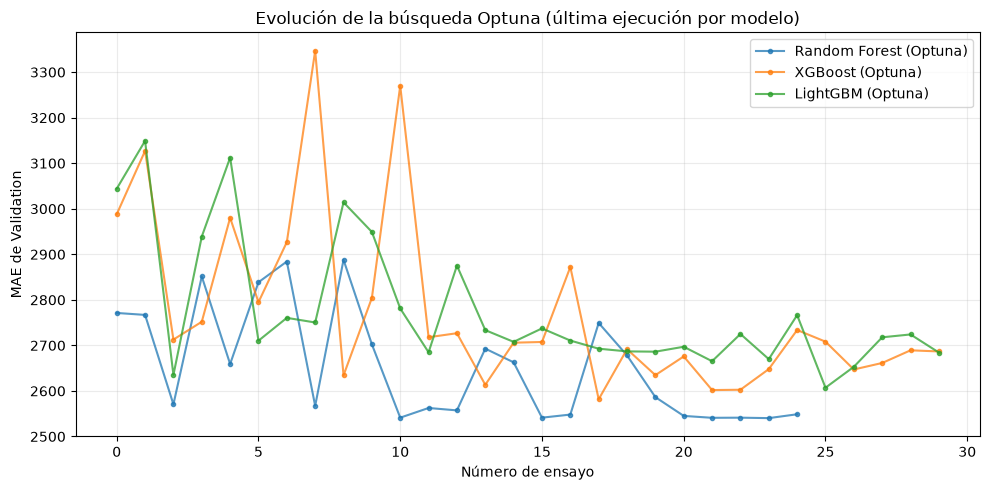

In [8]:
# Evolución de cada búsqueda más reciente según los logs.
fig, ax = plt.subplots(figsize=(10, 5))
for nombre in ["Random Forest (Optuna)", "XGBoost (Optuna)", "LightGBM (Optuna)"]:
    registros = experimentacion.loc[experimentacion["modelo"].eq(nombre)].copy()
    fecha_ultima = registros["timestamp_utc"].max()
    registros = registros.loc[registros["timestamp_utc"].eq(fecha_ultima)].copy()
    registros["trial"] = registros["hiperparametros"].map(
        lambda s: leer_parametros(s).get("optuna_trial", np.nan)
    )
    registros = registros.dropna(subset=["trial"]).sort_values("trial")
    if not registros.empty:
        ax.plot(registros["trial"], registros["MAE"], marker=".", alpha=0.75, label=nombre)
ax.set(title="Evolución de la búsqueda Optuna (última ejecución por modelo)",
       xlabel="Número de ensayo", ylabel="MAE de Validation")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### Decisión de modelado

En los ensayos, los algoritmos de árboles favorecieron configuraciones relativamente controladas (por ejemplo, profundidad baja en el mejor XGBoost y pocas hojas en el mejor LightGBM). Es compatible con una señal predictiva dominada por consumo reciente y estacionalidad, pero la explicación no es causal ni prueba que las relaciones sean lineales.

**Se fija LASSO con `alpha=300`** porque tuvo el menor MAE de Validation. Desde este punto no se modifica el conjunto de características ni el hiperparámetro para intentar mejorar el resultado de Test.

## 6. Diagnóstico del LASSO seleccionado

Para evitar evaluar el modelo **reentrenado** sobre las mismas filas de Validation con las que se ajustó, reproducimos el modelo de **selección** entrenando solo con Train. El escalador está dentro del `Pipeline` y se ajusta exclusivamente en esas 736 filas. Se utiliza el `alpha=300` ya seleccionado; esta sección no optimiza parámetros.

In [9]:
alpha = float(entrada["hiperparametros"]["alpha"])
assert alpha == 300.0

lasso_validacion = Pipeline([
    ("scaler", StandardScaler()),
    ("regresor", Lasso(alpha=alpha, max_iter=30000, random_state=SEMILLA)),
])
lasso_validacion.fit(train[features], train["target_manana"])
y_real = val["target_manana"].to_numpy(dtype=float)
y_pred = lasso_validacion.predict(val[features])
residuos = y_real - y_pred
error_abs = np.abs(residuos)

metricas = {
    "MAE": float(mean_absolute_error(y_real, y_pred)),
    "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
    "R2": float(r2_score(y_real, y_pred)),
}
display(pd.DataFrame([metricas]).round(3))

for nombre, valor in metricas.items():
    esperado = float(entrada["metricas_validation"][nombre])
    assert np.isclose(valor, esperado, atol=0.03), f"Diferencia en {nombre}: {valor} vs {esperado}"

print("Sesgo medio (real - predicho):", round(float(residuos.mean()), 2))
print("Mediana de error absoluto:", round(float(np.median(error_abs)), 2))
print("P90 de error absoluto:", round(float(np.percentile(error_abs, 90)), 2))
print("Error absoluto máximo:", round(float(error_abs.max()), 2))
print("Subestimaciones:", int((residuos > 0).sum()))
print("Sobreestimaciones:", int((residuos < 0).sum()))

,MAE,RMSE,R2
0,2364.995,2961.561,0.447


Sesgo medio (real - predicho): -535.13
Mediana de error absoluto: 2108.35
P90 de error absoluto: 4775.78
Error absoluto máximo: 9733.2
Subestimaciones: 69
Sobreestimaciones: 88


### 6.1 Predicciones frente a valores reales

La línea discontinua representa una predicción perfecta. La dispersión respecto de ella permite ver errores importantes y cierta tendencia a aproximar las predicciones hacia consumos intermedios.

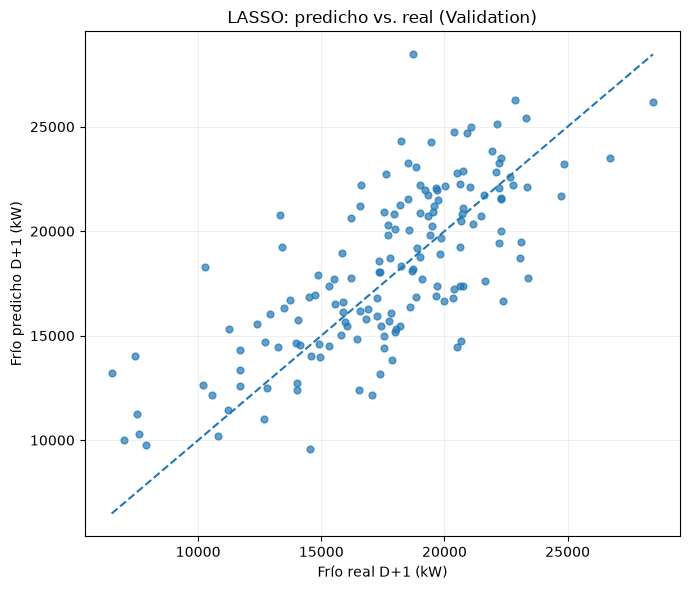

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_real, y_pred, s=24, alpha=0.7)
extremos = [float(min(y_real.min(), y_pred.min())), float(max(y_real.max(), y_pred.max()))]
ax.plot(extremos, extremos, "--", linewidth=1.5)
ax.set(xlabel="Frío real D+1 (kW)", ylabel="Frío predicho D+1 (kW)",
       title="LASSO: predicho vs. real (Validation)")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 6.2 Residuos frente a la predicción

Definimos el residuo como `real − predicho`: valores positivos indican subestimación y negativos indican sobreestimación. Buscamos si la dispersión cambia según el nivel de consumo o si aparecen errores sistemáticos.

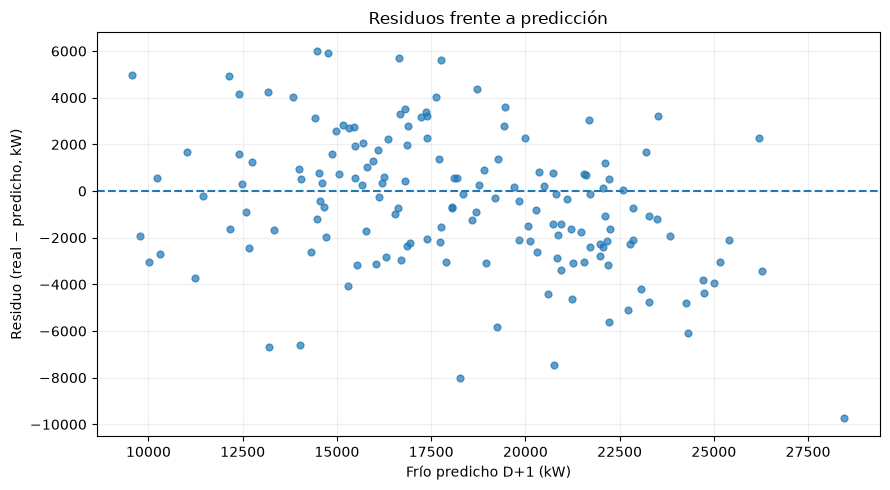

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(y_pred, residuos, s=24, alpha=0.7)
ax.axhline(0, linestyle="--", linewidth=1.5)
ax.set(xlabel="Frío predicho D+1 (kW)", ylabel="Residuo (real − predicho, kW)",
       title="Residuos frente a predicción")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 6.3 Evolución temporal de residuos

El gráfico temporal permite detectar si los errores aparecen agrupados en períodos específicos. En la ejecución revisada se observaron varias sobreestimaciones durante marzo–mayo de 2023. Esto es un indicio de posible cambio temporal, **no una explicación demostrada**.

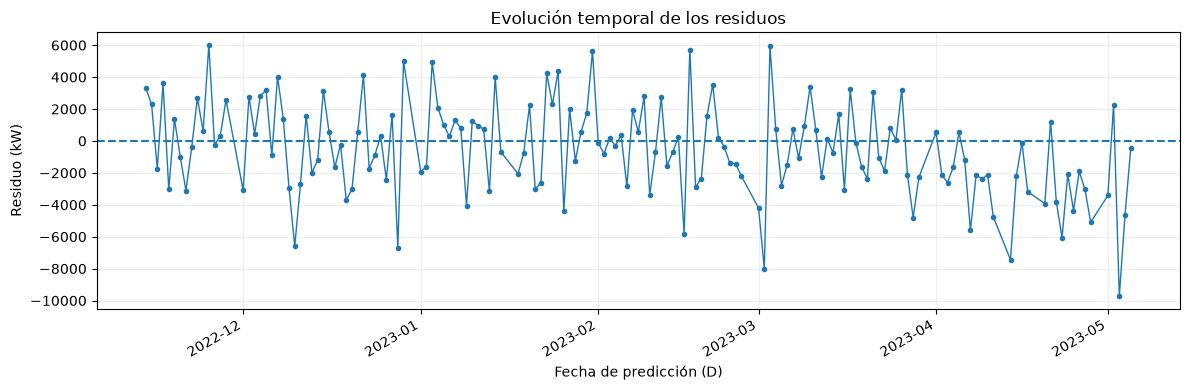

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(val["fecha"], residuos, marker=".", linewidth=1)
ax.axhline(0, linestyle="--", linewidth=1.5)
ax.set(xlabel="Fecha de predicción (D)", ylabel="Residuo (kW)",
       title="Evolución temporal de los residuos")
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 6.4 Distribución del error y casos extremos

Una media de residuos negativa corresponde a un sesgo de sobreestimación. Conviene analizar el tamaño de los errores extremos y no quedarse solamente con el MAE promedio.

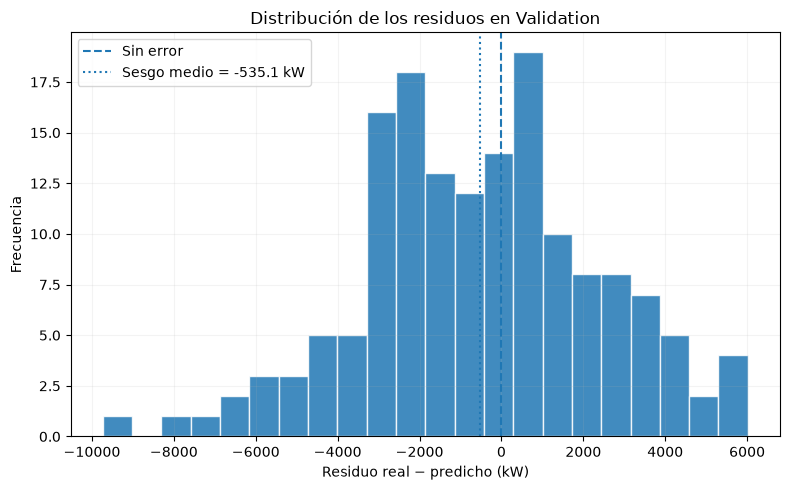

,fecha_D,fecha_D_mas_1,frio_real_D_mas_1,frio_predicho_D_mas_1,residuo_real_menos_predicho,error_absoluto
154,2023-05-03,2023-05-04,18731.0,28464.20,-9733.20,9733.20
100,2023-03-02,2023-03-03,10274.0,18272.98,-7998.98,7998.98
139,2023-04-14,2023-04-15,13306.0,20755.57,-7449.57,7449.57
42,2022-12-28,2022-12-29,6488.0,13192.70,-6704.70,6704.70
24,2022-12-10,2022-12-11,7420.0,14014.67,-6594.67,6594.67


In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(residuos, bins=22, edgecolor="white", alpha=0.85)
ax.axvline(0, linestyle="--", linewidth=1.5, label="Sin error")
ax.axvline(residuos.mean(), linestyle=":", linewidth=1.5,
           label=f"Sesgo medio = {residuos.mean():.1f} kW")
ax.set(xlabel="Residuo real − predicho (kW)", ylabel="Frecuencia",
       title="Distribución de los residuos en Validation")
ax.legend()
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

predicciones_validacion = pd.DataFrame({
    "fecha_D": val["fecha"].dt.strftime("%Y-%m-%d").to_numpy(),
    "fecha_D_mas_1": pd.to_datetime(val["fecha_siguiente"]).dt.strftime("%Y-%m-%d").to_numpy(),
    "frio_real_D_mas_1": y_real,
    "frio_predicho_D_mas_1": y_pred,
    "residuo_real_menos_predicho": residuos,
    "error_absoluto": error_abs,
})
display(predicciones_validacion.nlargest(5, "error_absoluto").round(2))

### 6.5 Coeficientes e interpretación

Como todas las variables del modelo lineal se estandarizan, podemos comparar sus coeficientes ajustados en una escala común. El signo indica la dirección de la asociación **manteniendo las demás variables constantes**. No deben interpretarse como efectos causales, especialmente por la correlación entre variables industriales.

,caracteristica,coef_estandarizado,magnitud
0,cos_anual,-2354.79,2354.79
1,frio_kw,2250.97,2250.97
2,EE | Servicios (Kw),952.36,952.36
3,EE | Planta (Kw),515.98,515.98
4,frio_lag_7d,385.89,385.89
5,GasVapor | Tot Vap Lav L3 / Hora,371.51,371.51
6,GasVapor | Vapor Cocina (Kg),312.84,312.84
7,Ratio | Frio sobre Servicios,241.85,241.85
8,Aire | Totaliador_Aire_L4,181.54,181.54
9,GasVapor | Tot_Vapor_CIP_Bodega,-149.64,149.64


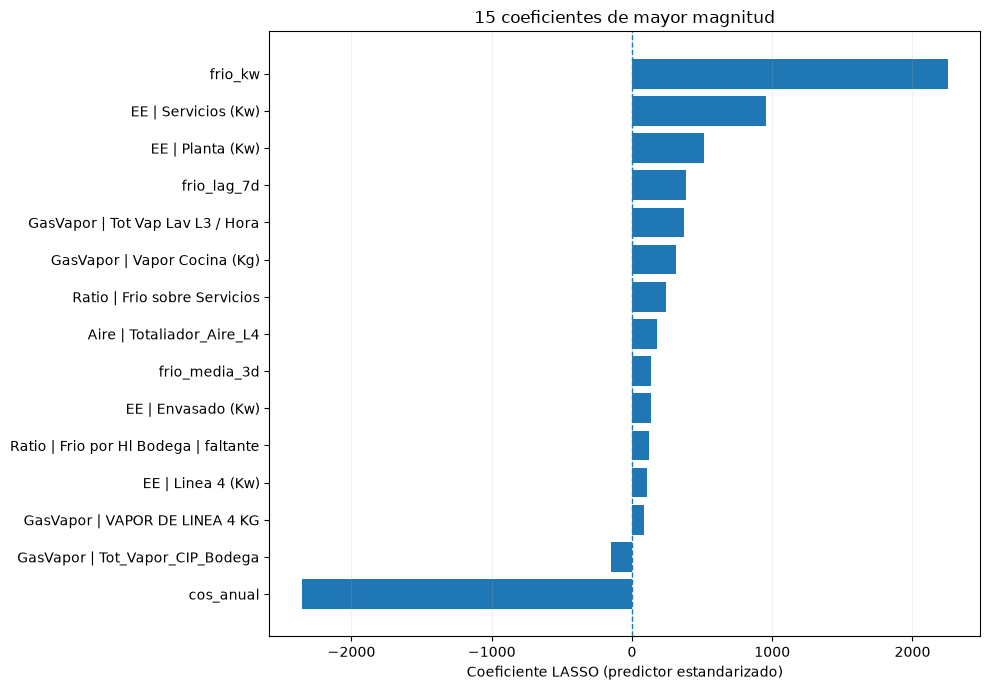

In [14]:
coeficientes = pd.DataFrame({
    "caracteristica": features,
    "coef_estandarizado": lasso_validacion.named_steps["regresor"].coef_,
})
coeficientes["magnitud"] = coeficientes["coef_estandarizado"].abs()
display(coeficientes.nlargest(10, "magnitud").round(2))

top = coeficientes.nlargest(15, "magnitud").sort_values("coef_estandarizado")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["caracteristica"], top["coef_estandarizado"])
ax.axvline(0, linestyle="--", linewidth=1)
ax.set(xlabel="Coeficiente LASSO (predictor estandarizado)",
       title="15 coeficientes de mayor magnitud")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

### Síntesis del diagnóstico

- **Sesgo medio:** aproximadamente **−535,13 kW**; hubo 88 sobreestimaciones y 69 subestimaciones.
- **Errores grandes:** el máximo fue aproximadamente **9.733,20 kW**; los casos de mayor error incluyeron consumos realmente bajos que fueron sobreestimados.
- **Variables dominantes:** `cos_anual` y `frio_kw`, seguidas de electricidad de Servicios y Planta, consumo de frío de siete días anteriores y variables de vapor.
- **Limitación:** el modelo no capta plenamente algunos descensos bruscos del consumo. Un R² próximo a 0,45 refleja capacidad explicativa moderada en Validation.

Estas limitaciones se informan aunque LASSO tenga el mejor MAE de los candidatos. No usamos el diagnóstico para elegir otra vez hiperparámetros sobre las mismas fechas.

## 7. Modelo final registrado: v1.0.0

Después de elegir LASSO usando Train → Validation, `src/train_model.py --finalizar` reajustó **StandardScaler + LASSO** usando las **893 filas de Train + Validation**, sin cambiar `alpha`. El pipeline completo se serializó con joblib como `models/modelo_v1.0.0.pkl`.

El archivo `models/model_registry.json` identifica la versión, las 22 variables ordenadas, el script, el commit, las métricas **anteriores al reajuste** y los hashes SHA-256. **No se calculan métricas de Validation sobre el modelo reentrenado**, ya que esas filas se usaron para ajustarlo.

In [15]:
ruta_modelo = RAIZ / entrada["path"]
if not ruta_modelo.is_file():
    raise FileNotFoundError(f"No existe el modelo serializado: {ruta_modelo}")

sha_modelo = hashlib.sha256(ruta_modelo.read_bytes()).hexdigest()
assert sha_modelo == entrada["modelo_sha256"], "El modelo no coincide con su hash registrado."

# joblib/pickle solo se debe cargar cuando el archivo procede de una fuente confiable.
modelo_final = joblib.load(ruta_modelo)
assert isinstance(modelo_final, Pipeline)
assert list(modelo_final.feature_names_in_) == features
assert np.isclose(modelo_final.named_steps["regresor"].alpha, 300.0)
assert entrada["git_commit"] and len(entrada["git_commit"]) == 40
assert entrada["reentrenamiento"]["filas"] == len(train) + len(val)

print("Versión:", version)
print("Modelo:", entrada["modelo"])
print("Ruta:", entrada["path"])
print("Commit de código:", entrada["git_commit"])
print("Entrenado con filas:", entrada["reentrenamiento"]["filas"])
print("Características:", len(entrada["features"]))
print("SHA-256 del modelo: OK")
print("Pipeline serializado: OK")
print("Test NO se evaluó en este notebook.")

Versión: v1.0.0
Modelo: LASSO
Ruta: models/modelo_v1.0.0.pkl
Commit de código: 96400575d16401eccd677faee17a1f52e73fefde
Entrenado con filas: 893
Características: 22
SHA-256 del modelo: OK
Pipeline serializado: OK
Test NO se evaluó en este notebook.


## 8. Reproducibilidad y comandos del proyecto

Todo el entrenamiento se ejecuta desde la **raíz** del repositorio, con las dependencias instaladas y con la semilla 42.

```powershell
# Evaluación y optimización (requiere tiempo; añade nuevos logs)
python src/train_model.py

# Diagnóstico de la configuración seleccionada (solo Train/Validation)
python src/diagnostico_validacion.py

# Finalización y registro: SOLO para una versión que aún no exista
python src/train_model.py --finalizar
```

**Atención:** `--finalizar` no sobrescribe `modelo_v1.0.0.pkl`; no hace falta volver a ejecutarlo para abrir este notebook. La sesión aquí documentada ya generó y verificó dicho modelo.

En `results/experiment_logs.csv` hay ejecuciones repetidas; el notebook resume el mejor MAE por familia para compararlas, y el `git_commit` permite auditar qué código produjo cada registro. La serialización se valida mediante el hash y la recarga. Al crear la etiqueta Git `v1.0.0`, debe documentarse qué commit corresponde al código de entrenamiento y cuál contiene los artefactos de la versión.

## 9. Conclusiones y decisiones

1. **El modelo seleccionado agrega valor en Validation, pero con una mejora acotada.** LASSO logró MAE ≈ 2.365 frente a ≈ 2.492,70 del baseline más exigente (media móvil), una reducción de ≈ 5,12 %. La conclusión final dependerá de la evaluación sobre el mismo Test.
2. **La complejidad no garantizó una mejor predicción.** Los ensayos de Random Forest, XGBoost y LightGBM no superaron al modelo lineal regularizado con las 22 variables elegidas.
3. **La dependencia temporal es clave.** Las variables `frio_kw`, `frio_lag_7d` y `cos_anual` contienen información del día D y anteriores; **no se utilizan consumos de D+1 como predictores**. Su relación con el objetivo se interpreta sin confundir correlación con causalidad.
4. **La regularización aporta parsimonia.** LASSO aprovecha el conjunto reducido y evita sumar complejidad cuando no mejora el MAE de Validation.
5. **Quedan limitaciones:** sobreestimación media, errores altos en caídas bruscas del consumo, ventanas incompletas para la media móvil y posible cambio temporal en los residuos. No se modificó el modelo a partir de estos hallazgos para evitar un nuevo ajuste sobre Validation.

### Pendiente para el cierre del trabajo

- Evaluar **una sola vez**, sobre el mismo conjunto final de Test, el MAE del modelo y los dos baselines, y comprobar si los supera; la consigna también exige **MAE < 3000** en el test oculto.
- Construir `src/predict.py` que reutilice exactamente el preprocesamiento, gestione cambios de hojas/columnas y escriba una predicción por día.
- En el informe final responder con números las cinco preguntas de la consigna: valor aportado, variables parecidas al objetivo, patrón semanal, umbral mínimo de mejora y técnicas descartadas con justificación.

Este notebook cierra el análisis de Train y Validation; no contiene una evaluación final de Test.